# Step 11: looking inside Gemma, stages 0 and 1

Plan, committed before these were run: [PLAN_11.md](PLAN_11.md). The heavy work runs in `venv_gpu` (see `inside.py`); this notebook only reads its saved results.

- **Stage 0:** does Gemma in `transformers` give the same answers as llama.cpp did in step 10?
- **Stage 1:** probes. At the position just before the answer word, can a straight-line classifier read (T1) its answer, (T2) the 1-day move, (T3) what its named rule says?

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

OUT = Path("..") / "results" / "inside"  # not in git

## Stage 0: the same answers as llama.cpp?

200 build-month questions, replayed with llama.cpp's own reply up to `"answer": "`. **Gate: at least 90% the same.**

In [2]:
versions = {"4-bit NF4 (the plan)": "stage0_reproduce.csv", "8-bit (added after looking)": "stage0_reproduce_8bit.csv"}
same = {}
for name, file in versions.items():
    t = pd.read_csv(OUT / file)
    same[name] = t.groupby("run")["same"].mean().mul(100).round(1)
    same[name]["all 200"] = round(100 * t["same"].mean(), 1)
    print(name)
    display(pd.crosstab(t["answer"], t["transformers"], rownames=["llama.cpp"], colnames=["transformers"]))
pd.DataFrame(same)

4-bit NF4 (the plan)


transformers,down,up
llama.cpp,,
down,74,0
up,33,93


8-bit (added after looking)


transformers,down,up
llama.cpp,,
down,63,11
up,17,109


,4-bit NF4 (the plan),8-bit (added after looking)
run,,
planted_none,76.1,85.1
planted_tester,89.6,83.6
real_none,84.8,89.4
all 200,83.5,86.0


**The gate failed in both.** NF4's differences all go one way (llama.cpp "up", NF4 "down"); 8-bit's go both ways. So stages 2–4 can't be claimed for the llama.cpp model, and stage 1 runs on 8-bit.

## Stage 1: probes

For every layer, a logistic regression is trained on build months (2017–2018) and scored once on score months (2019).

- **Score:** balanced accuracy, the average of the hit rates on "up" and on "down". Always saying one word scores 50%.
- **Controls:** the same probe on shuffled labels; and the average of the question's input embeddings (which words appear, not their order or anything the layers work out).
- **T3** is trained on the two "none" runs and judged on **conflict questions**, where its rule's answer differs from the 1-day move. It is also scored on the **other questions**: a probe that only flips the 1-day move would pass the first and fail the second.

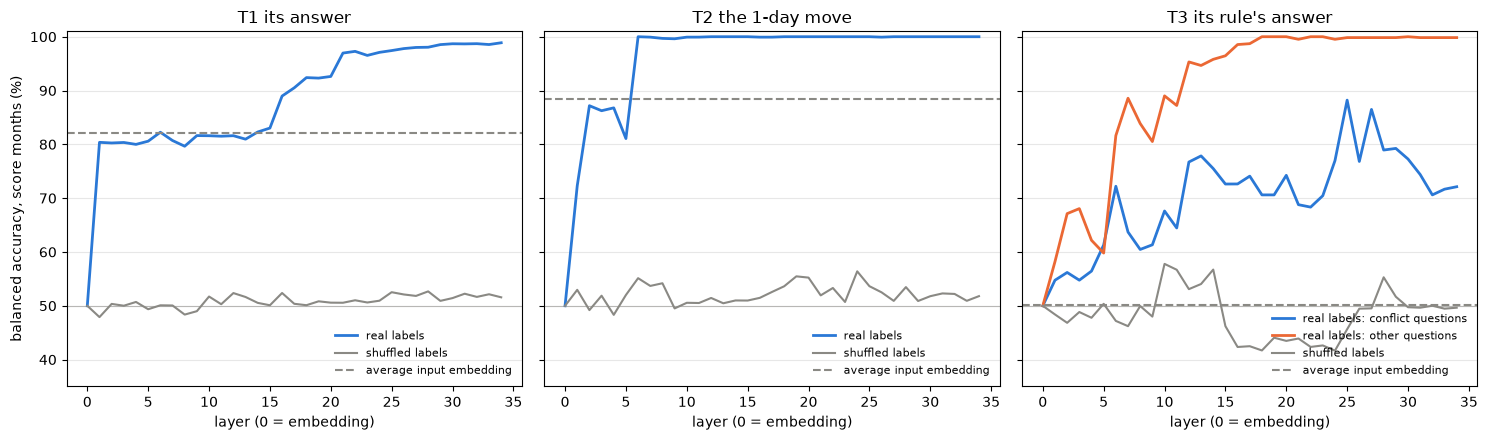

In [3]:
probes = pd.read_csv(OUT / "stage1_probes.csv")
layers = probes[probes["input"].str.startswith("layer")].assign(layer=lambda t: t["input"].str.split().str[1].astype(int))
words = probes[probes["input"] == "average input embedding"].set_index(["target", "labels"])

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8984"
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, (target, t) in zip(axes, layers.groupby("target", sort=False)):
    real, shuffled = t[t["labels"] == "real"], t[t["labels"] == "shuffled"]
    ax.plot(real["layer"], 100 * real["judged"], color=BLUE, lw=2, label="real labels" + (": conflict questions" if "T3" in target else ""))
    if "T3" in target:
        ax.plot(real["layer"], 100 * real["T3 other questions"], color=ORANGE, lw=2, label="real labels: other questions")
    ax.plot(shuffled["layer"], 100 * shuffled["judged"], color=GRAY, lw=1.5, label="shuffled labels")
    ax.axhline(100 * words.loc[(target, "real"), "judged"], color=GRAY, ls="--", lw=1.5, label="average input embedding")
    ax.axhline(50, color=GRAY, lw=0.8, alpha=0.5)
    ax.set_title(target)
    ax.set_xlabel("layer (0 = embedding)")
    ax.grid(axis="y", alpha=0.3)
    ax.legend(loc="lower right", fontsize=8, frameon=False)
axes[0].set_ylabel("balanced accuracy, score months (%)")
axes[0].set_ylim(35, 101)
plt.tight_layout()
plt.show()

The best layer per target, with the controls. The best layer is picked on the score months, so it flatters a little: **"shuffled, highest at any layer"** shows how high picking the best of 35 noisy layers reaches by luck alone.

In [4]:
rows = {}
for target, t in layers.groupby("target", sort=False):
    real, shuffled = t[t["labels"] == "real"].set_index("layer"), t[t["labels"] == "shuffled"].set_index("layer")
    best = real["judged"].idxmax()
    rows[target] = {"best layer": best, "real": real.loc[best, "judged"], "shuffled, same layer": shuffled.loc[best, "judged"],
                    "shuffled, highest at any layer": shuffled["judged"].max(),
                    "average input embedding": words.loc[(target, "real"), "judged"],
                    **{f"real, {run}": real.loc[best, run] for run in ["planted_tester", "planted_none", "real_none"]},
                    "real, other questions (T3)": real.loc[best].get("T3 other questions")}
summary = pd.DataFrame(rows).T
summary.iloc[:, 1:] = summary.iloc[:, 1:].astype(float).mul(100).round(1)
summary

,best layer,real,"shuffled, same layer","shuffled, highest at any layer",average input embedding,"real, planted_tester","real, planted_none","real, real_none","real, other questions (T3)"
T1 its answer,34.0,98.9,51.6,52.7,82.1,97.2,98.0,99.3,NaN
T2 the 1-day move,6.0,100.0,55.1,56.4,88.5,100.0,100.0,100.0,NaN
T3 its rule's answer,25.0,88.2,45.6,57.8,50.2,81.2,99.3,100.0,99.8


The first layer where each target reaches 90%, and T3 at every fifth layer.

In [5]:
real = layers[layers["labels"] == "real"]
print({target: (t.loc[t["judged"] >= 0.9, "layer"].min() if (t["judged"] >= 0.9).any() else None)
       for target, t in real.groupby("target", sort=False)})
t3 = real[real["target"].str.startswith("T3")].set_index("layer")
t3.loc[::5, ["judged", "T3 other questions", "planted_tester", "planted_none", "real_none"]].mul(100).round(1)

{'T1 its answer': np.int64(17), 'T2 the 1-day move': np.int64(6), "T3 its rule's answer": None}


,judged,T3 other questions,planted_tester,planted_none,real_none
layer,,,,,
0,50.0,50.0,50.0,50.0,50.0
5,61.3,59.8,48.2,68.1,61.9
10,67.6,89.0,46.9,87.4,89.2
15,72.6,96.5,57.9,95.5,97.8
20,74.2,100.0,58.9,100.0,100.0
25,88.2,99.8,81.2,99.3,100.0
30,77.3,100.0,64.0,100.0,99.1


## What the T3 probe reads (added after looking)

A probe could pass T3 without reading the rule: by reading "the opposite of its answer". To tell them apart, split the 2019 questions by whether its own answer agreed with its rule. The share where the probe gives **its rule's answer**:

- A probe that reads the rule scores high in **every** column.
- One that reads "the opposite of its answer" scores high where it disagreed and **low where it agreed**.

Made by `inside.py t3check`.

In [6]:
check = pd.read_csv(OUT / "stage1_t3_check.csv", index_col="layer")
check.iloc[:-1] = check.iloc[:-1].mul(100).round(1)
check

,"none runs, it disagreed with its rule","none runs, it agreed","planted tester, it disagreed","planted tester, it agreed"
layer,,,,
15,96.6,98.4,77.8,22.3
20,100.0,100.0,77.8,24.5
25,99.7,99.8,86.0,73.4
30,99.7,100.0,79.2,36.7
questions,351.0,513.0,293.0,139.0


Does 8-bit Gemma behave like step 10's llama.cpp model? 2019 questions, % (rule = its named rule's answer).

In [7]:
t = pd.read_csv(OUT / "activations_8bit.csv")
t = t[t["half"] == "score"]
pd.DataFrame({
    "llama.cpp agrees with its rule": (t["answer"] == t["rule_answer"]).groupby(t["run"]).mean(),
    "8-bit agrees with its rule": (t["own"] == t["rule_answer"]).groupby(t["run"]).mean(),
    "llama.cpp copies the 1-day move": (t["answer"] == t["move_1"]).groupby(t["run"]).mean(),
    "8-bit copies the 1-day move": (t["own"] == t["move_1"]).groupby(t["run"]).mean(),
    "8-bit = llama.cpp": (t["own"] == t["answer"]).groupby(t["run"]).mean(),
}).mul(100).round(1)

,llama.cpp agrees with its rule,8-bit agrees with its rule,llama.cpp copies the 1-day move,8-bit copies the 1-day move,8-bit = llama.cpp
run,,,,,
planted_none,59.3,56.7,60.9,63.4,85.4
planted_tester,35.2,32.2,64.8,67.8,85.4
real_none,64.4,62.0,61.6,63.9,85.6


## Conclusions

**In the "none" runs, Gemma works out what its rule says and then often answers something else (explanation 2).** In the planted tester run, the run the question was about, the probes can't settle it.

| Expected | Result |
|---|---|
| T1, its answer: ≥ 95% | **Yes:** 98.9% at layer 34, and over 90% from layer 17 |
| T2, the 1-day move: ≥ 90% | **Yes:** 100% from layer 6 |
| T3 on conflict questions: 60–75% | **Higher:** 88.2% at layer 25, and 68–88% at every layer from 12. But see below |
| Shuffled labels: about 50% (T3: at most 55%) | **Yes** at the best layers (45.6–55.1%). The highest at any layer is 57.8% (T3, layer 10): luck from picking among 35 layers |
| Average input embedding: about 50% | **Only for T3** (50.2%). For T1 and T2 it is 82–89%: which words appear already gives away most of the 1-day move, and so most of its answer |

By the plan's rule (T3 ≥ 65% with both controls ≤ 55%), explanation 2 is supported. The check added after looking says where it holds:

- **None runs: clearly.** At layers 20–30 the probe gives the rule's answer on 99.7–100% of 2019 questions, including the 351 where Gemma then answered the opposite. The words alone can't do it (50.2%), so the layers work it out.
- **Planted tester: not settled.** Only at layer 25 does the probe read the rule both where Gemma agreed (73%) and where it didn't (86%). At layers 15, 20 and 30 it mostly gives "the opposite of its answer" (22–37% where it agreed). A probe can't be trained on this run alone: there the rule is always "reverse", so its answer is always the opposite of the 1-day move, and the two can't be told apart.
- **So the combined 88.2% flatters.** In planted tester, the questions where it disagreed are exactly those where it copied the 1-day move, so "the opposite of its answer" scores there too.
- **8-bit behaves like step 10's model overall,** even though single answers differ (85% the same): it agrees with its rule 32–62% of the time (llama.cpp 35–64%) and copies the 1-day move 63–68% (llama.cpp 61–65%).

**What it means:** the up habit or copying is not because it can't work out its rule. In the none runs it clearly does, and still answers against it on 41% of questions (351 of 864). Under the plan, stages 2–4 don't run, because stage 0's gate failed.